In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

DATA_DIR = Path("../data/raw")

df = pd.read_csv(DATA_DIR / "UpdatedResumeDataSet.csv")
df = df.dropna(subset=["Resume"]).drop_duplicates(subset=["Resume"])
df["Resume"] = df["Resume"].astype(str)

print("Resumes available:", len(df))
display(df[["Category", "Resume"]].head())

Resumes available: 166


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."


In [2]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X = vectorizer.fit_transform(df["Resume"])

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (166, 5000)


In [3]:
number_of_clusters = min(5, len(df))

kmeans = KMeans(
    n_clusters=number_of_clusters,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X)

display(df[["Category", "Cluster"]].head(20))
print(df["Cluster"].value_counts().sort_index())

,Category,Cluster
0,Data Science,4
1,Data Science,3
2,Data Science,3
3,Data Science,4
4,Data Science,3
5,Data Science,3
6,Data Science,4
7,Data Science,4
8,Data Science,4
9,Data Science,4


Cluster
0    18
1    36
2    11
3    41
4    60
Name: count, dtype: int64


In [4]:
terms = vectorizer.get_feature_names_out()

for cluster_id, center in enumerate(kmeans.cluster_centers_):
    top_indices = center.argsort()[-10:][::-1]
    top_words = [terms[i] for i in top_indices]

    print(f"Cluster {cluster_id}: {', '.join(top_words)}")

Cluster 0: test, testing, automation, project, manual, cases, months, tester, business, functional
Cluster 1: details, hr, january, company, mumbai, legal, law, civil, exprience, advocate
Cluster 2: database, oracle, server, sql, servers, backup, databases, installation, rman, mysql
Cluster 3: exprience, months, java, year, developer, details, pune, python, maharashtra, net
Cluster 4: data, project, sap, hadoop, sales, exprience, business, months, company, management


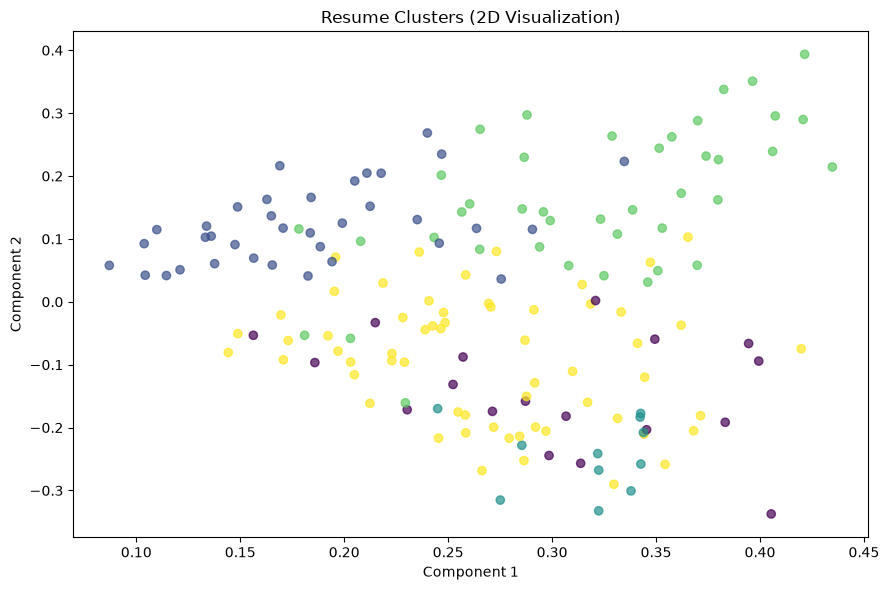

In [5]:
if X.shape[1] >= 2:
    svd = TruncatedSVD(n_components=2, random_state=42)
    reduced = svd.fit_transform(X)

    plt.figure(figsize=(9, 6))
    plt.scatter(
        reduced[:, 0],
        reduced[:, 1],
        c=df["Cluster"],
        alpha=0.7
    )
    plt.title("Resume Clusters (2D Visualization)")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough features for a 2D plot.")